# Rectified Flow Matching Face-Swap — Kaggle-Optimized Training Notebook

This notebook replaces the original GAN training game with **conditional Rectified / Flow Matching**. The target velocity follows the critique's straight-line path:

\[
 x_t=(1-t)x_0+t x_1,\qquad u_t=x_1-x_0,
\]
\[
 \mathcal L_{FM}=\mathbb E\left[\|v_	heta(x_t,t,c)-(x_1-x_0)\|_2^2
ight].
\]

The implementation is intentionally different from the supplied GAN:

- no discriminator, adversarial loss, or GAN minimax loop;
- no AdaIN / InstanceNorm identity injection;
- spatial conditioning comes from the source face crop;
- target identity is injected through a frozen VGGFace2 embedding plus a small bottleneck identity cross-attention path;
- BiSeNet face boxes and VGGFace2 embeddings are cached **once** before training;
- inference uses deterministic few-step ODE integration (default: 4-step Heun);
- AMP uses FP16 only when safe, otherwise BF16 when supported, with the loss and flow target kept in FP32 to reduce NaN risk;
- a runtime batch-size benchmark chooses the highest-throughput candidate that stays below conservative VRAM/RAM limits;
- tqdm shows ETA, throughput, loss, LR, GPU memory, and host RAM;
- JSONL/CSV logs capture training, hardware, timing, memory, NaN/Inf guards, and environment details;
- checkpoints are atomic and aggressively pruned so the working directory stays well below Kaggle's 30 GB limit.

**Ground-truth note:** the original notebook explicitly treats `swapped_aux` as an auxiliary/pseudo-supervision signal rather than strict ground truth. This notebook therefore labels it `ground_truth` in saved visuals for convenience, but the run metadata calls it **proxy GT / swapped reference**. The exact true paired ground-truth swap is not present in the provided dataset description.

## 0. Design choices derived from the supplied critique

The critique identifies discriminator overpowering, adversarial oscillation, and the high-latency/low-memory pattern as key baseline problems. It proposes Rectified Flow as a deterministic vector-field regression alternative and gives the straight-line interpolation and MSE flow-matching objective above. The implementation below follows that mathematical direction rather than trying to patch the GAN.

In [1]:
# ============================================================
# CELL 1 — Environment, imports, reproducibility, runtime probes
# ============================================================
import os, sys, gc, re, json, math, time, glob, shutil, random, hashlib, subprocess, platform, socket
from pathlib import Path
from datetime import datetime, timezone
from contextlib import nullcontext

# Kaggle-specific CUDA allocator setting should be set before significant allocations.
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")


def ensure_package(import_name: str, pip_name: str):
    try:
        __import__(import_name)
    except Exception:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--no-deps", pip_name])

# Keep Kaggle's preinstalled torch/torchvision stack intact.
ensure_package("kornia", "kornia")
ensure_package("facenet_pytorch", "facenet-pytorch")

import numpy as np
import pandas as pd
from PIL import Image
import psutil
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from tqdm.auto import tqdm
import torchvision.utils as vutils
import matplotlib.pyplot as plt
import kornia
from facenet_pytorch import InceptionResnetV1

print("Python:", sys.version)
print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("CUDA version:", torch.version.cuda)
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}: {torch.cuda.get_device_name(i)}")
        props = torch.cuda.get_device_properties(i)
        print(f"  VRAM: {props.total_memory/1024**3:.2f} GiB | SMs: {props.multi_processor_count}")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
torch.set_float32_matmul_precision("high")

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
assert DEVICE.type == "cuda", "This notebook is designed for a Kaggle CUDA GPU runtime."

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 21.4 MB/s eta 0:00:00
Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
Torch: 2.10.0+cu128
CUDA available: True
CUDA version: 12.8
GPU 0: Tesla T4
  VRAM: 14.56 GiB | SMs: 40
GPU 1: Tesla T4
  VRAM: 14.56 GiB | SMs: 40


In [2]:
# ============================================================
# CELL 2 — Exact dataset paths preserved from the supplied notebook
# ============================================================
SWAPPED_DIR = "/kaggle/input/datasets/syedajannatulnaim/deepfakeface-swapped-images-using-ffhq-dataset/flickr_deepfake"
FFHQ_DIR = "/kaggle/input/datasets/arnaud58/flickrfaceshq-dataset-ffhq"
SEG_CHECKPOINT = "/kaggle/input/models/nilanjansaha123/the-7999/pytorch/default/1/79999_iter.pth"

# Working/output area only — never write generated training data into /kaggle/input.
RUN_ROOT = Path("/kaggle/working/rectified_flow_matching")
CACHE_DIR = RUN_ROOT / "cache"
CKPT_DIR = RUN_ROOT / "checkpoints"
VIS_DIR = RUN_ROOT / "visuals"
LOG_DIR = RUN_ROOT / "logs"
for d in [RUN_ROOT, CACHE_DIR, CKPT_DIR, VIS_DIR, LOG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 512
CROP_SIZE = 256
LIMIT_SAMPLES = None                 # set to an integer for a debug run
USE_SWAPPED_AS_PROXY_GT = True       # required for supervised/paired flow target
TRAIN_FRACTION = 0.98
VAL_MAX_SAMPLES = 512                # fixed-size validation subset to control epoch overhead
NUM_EPOCHS = 10
MAX_TRAIN_STEPS = None               # e.g. 20000 for a controlled Kaggle run

# Runtime optimization knobs.
AUTO_TUNE_BATCH = True
BATCH_CANDIDATES = [1, 2, 4, 8, 16, 32]
AUTO_TUNE_WARMUP_STEPS = 2
AUTO_TUNE_TIMED_STEPS = 5
VRAM_SAFETY_FRACTION = 0.88          # reject candidates whose peak allocation is too close to the limit
HOST_RAM_SAFETY_FRACTION = 0.75
NUM_WORKERS = 2                       # kept conservative; persistent workers are enabled when > 0
PIN_MEMORY = True
PREFETCH_FACTOR = 2

# AMP: FP16 gets GradScaler; BF16 does not need a scaler. The FP32 loss path is intentional.
USE_AMP = True
PREFER_BF16 = False
TRY_TORCH_COMPILE = True
GRAD_CLIP_NORM = 1.0
LR = 2e-4
BETAS = (0.9, 0.99)
WEIGHT_DECAY = 1e-4
WARMUP_FRACTION = 0.05

# Rectified-flow sampling for epoch visuals.
SAMPLE_STEPS = 4
SAMPLE_SOLVER = "heun"              # "euler" or "heun"
N_VIS_SAMPLES = 4

# Logging/checkpoint cadence and disk policy.
LOG_EVERY_STEPS = 25
GPU_QUERY_INTERVAL_SEC = 60
CHECKPOINT_EVERY_STEPS = 5000
KEEP_STEP_CHECKPOINTS = 3
WORKING_SOFT_LIMIT_GB = 24.0         # prune well before Kaggle's 30 GB hard limit
MIN_FREE_GB_BEFORE_CKPT = 2.0
RESUME = True


def write_json(path, obj):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2, default=str)
    os.replace(tmp, path)

config = {k: v for k, v in globals().copy().items() if k.isupper() and not k.startswith("__")}
config.update({"timestamp_utc": datetime.now(timezone.utc).isoformat(), "device": str(DEVICE)})
write_json(RUN_ROOT / "run_config.json", config)

assert Path(SWAPPED_DIR).exists(), f"Missing swapped dataset: {SWAPPED_DIR}"
assert Path(FFHQ_DIR).exists(), f"Missing FFHQ dataset: {FFHQ_DIR}"
assert Path(SEG_CHECKPOINT).exists(), f"Missing BiSeNet checkpoint: {SEG_CHECKPOINT}"

In [3]:
# ============================================================
# CELL 3 — Low-overhead system/hardware logger
# ============================================================
_proc = psutil.Process(os.getpid())
_last_gpu_query = 0.0
_last_gpu_info = None


def disk_usage_kaggle():
    u = shutil.disk_usage("/kaggle/working")
    return {"free_gb": u.free/1024**3, "used_gb": u.used/1024**3, "total_gb": u.total/1024**3}


def working_tree_size_gb():
    total = 0
    for root, dirs, files in os.walk(RUN_ROOT):
        for fn in files:
            try:
                total += os.path.getsize(os.path.join(root, fn))
            except OSError:
                pass
    return total / 1024**3


def nvidia_smi_snapshot(force=False):
    global _last_gpu_query, _last_gpu_info
    now = time.time()
    if (not force) and (now - _last_gpu_query < GPU_QUERY_INTERVAL_SEC):
        return _last_gpu_info
    if not torch.cuda.is_available():
        return None
    try:
        query = "index,name,utilization.gpu,memory.used,memory.total,temperature.gpu,power.draw,clocks.sm"
        out = subprocess.check_output(
            ["nvidia-smi", f"--query-gpu={query}", "--format=csv,noheader,nounits"],
            text=True, stderr=subprocess.STDOUT, timeout=5,
        )
        rows = []
        for line in out.strip().splitlines():
            parts = [p.strip() for p in line.split(",")]
            if len(parts) == 8:
                rows.append({
                    "index": int(parts[0]), "name": parts[1], "util_gpu_pct": float(parts[2]),
                    "mem_used_mb": float(parts[3]), "mem_total_mb": float(parts[4]),
                    "temperature_c": float(parts[5]), "power_w": float(parts[6]), "clock_sm_mhz": float(parts[7]),
                })
        _last_gpu_info = rows
        _last_gpu_query = now
        return rows
    except Exception as e:
        _last_gpu_info = {"error": str(e)}
        _last_gpu_query = now
        return _last_gpu_info


def runtime_snapshot(flow_model=None, optimizer=None, scaler=None):
    snap = {
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "hostname": socket.gethostname(),
        "pid": os.getpid(),
        "python": sys.version.split()[0],
        "platform": platform.platform(),
        "cpu_count": os.cpu_count(),
        "cpu_percent": psutil.cpu_percent(interval=None),
        "loadavg": list(os.getloadavg()) if hasattr(os, "getloadavg") else None,
        "host_rss_gb": _proc.memory_info().rss/1024**3,
        "host_vms_gb": _proc.memory_info().vms/1024**3,
        "host_ram_total_gb": psutil.virtual_memory().total/1024**3,
        "host_ram_used_gb": psutil.virtual_memory().used/1024**3,
        "host_ram_available_gb": psutil.virtual_memory().available/1024**3,
        "disk": disk_usage_kaggle(),
        "run_root_gb": working_tree_size_gb(),
        "gpu_smi": nvidia_smi_snapshot(),
    }
    if torch.cuda.is_available():
        snap["gpu_torch"] = {
            "allocated_gb": torch.cuda.memory_allocated(0)/1024**3,
            "reserved_gb": torch.cuda.memory_reserved(0)/1024**3,
            "peak_allocated_gb": torch.cuda.max_memory_allocated(0)/1024**3,
            "peak_reserved_gb": torch.cuda.max_memory_reserved(0)/1024**3,
            "free_gb_driver": torch.cuda.mem_get_info()[0]/1024**3,
            "total_gb_driver": torch.cuda.mem_get_info()[1]/1024**3,
        }
    if optimizer is not None:
        try:
            snap["learning_rates"] = [float(g["lr"]) for g in optimizer.param_groups]
        except Exception:
            pass
    if scaler is not None:
        try:
            snap["amp_scale"] = float(scaler.get_scale())
        except Exception:
            pass
    if flow_model is not None:
        snap["params_trainable"] = sum(p.numel() for p in flow_model.parameters() if p.requires_grad)
        snap["params_total"] = sum(p.numel() for p in flow_model.parameters())
    return snap


def append_jsonl(path, row):
    with open(path, "a") as f:
        f.write(json.dumps(row, default=str) + "\n")

write_json(RUN_ROOT / "system_start.json", runtime_snapshot())
try:
    subprocess.run([sys.executable, "-m", "pip", "freeze"], check=False,
                   stdout=open(RUN_ROOT / "pip_freeze.txt", "w"), stderr=subprocess.STDOUT)
except Exception:
    pass

In [4]:
# ============================================================
# CELL 4 — BiSeNet architecture copied from the supplied notebook
# This is used only for one-time face-box caching / visual compositing.
# ============================================================
FACE_CLASS_IDS = [1, 2, 3, 4, 5, 6, 10, 11, 12, 13]

class BasicBlock(nn.Module):
    def __init__(self, in_chan, out_chan, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_chan, out_chan, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_chan)
        self.conv2 = nn.Conv2d(out_chan, out_chan, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_chan)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = None
        if in_chan != out_chan or stride != 1:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_chan, out_chan, 1, stride, bias=False),
                nn.BatchNorm2d(out_chan),
            )
    def forward(self, x):
        residual = F.relu(self.bn1(self.conv1(x)))
        residual = self.bn2(self.conv2(residual))
        shortcut = self.downsample(x) if self.downsample is not None else x
        return self.relu(shortcut + residual)

def create_layer_basic(in_chan, out_chan, bnum, stride=1):
    layers = [BasicBlock(in_chan, out_chan, stride=stride)]
    for _ in range(bnum - 1):
        layers.append(BasicBlock(out_chan, out_chan, 1))
    return nn.Sequential(*layers)

class Resnet18(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 64, 7, 2, 3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.maxpool = nn.MaxPool2d(3, 2, 1)
        self.layer1 = create_layer_basic(64, 64, 2, 1)
        self.layer2 = create_layer_basic(64, 128, 2, 2)
        self.layer3 = create_layer_basic(128, 256, 2, 2)
        self.layer4 = create_layer_basic(256, 512, 2, 2)
    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.maxpool(x)
        x = self.layer1(x)
        feat8 = self.layer2(x)
        feat16 = self.layer3(feat8)
        feat32 = self.layer4(feat16)
        return feat8, feat16, feat32

class ConvBNReLU(nn.Module):
    def __init__(self, in_chan, out_chan, ks=3, stride=1, padding=1):
        super().__init__()
        self.conv = nn.Conv2d(in_chan, out_chan, ks, stride, padding, bias=False)
        self.bn = nn.BatchNorm2d(out_chan)
    def forward(self, x):
        return F.relu(self.bn(self.conv(x)))

class BiSeNetOutput(nn.Module):
    def __init__(self, in_chan, mid_chan, n_classes):
        super().__init__()
        self.conv = ConvBNReLU(in_chan, mid_chan)
        self.conv_out = nn.Conv2d(mid_chan, n_classes, 1, bias=False)
    def forward(self, x):
        return self.conv_out(self.conv(x))

class AttentionRefinementModule(nn.Module):
    def __init__(self, in_chan, out_chan):
        super().__init__()
        self.conv = ConvBNReLU(in_chan, out_chan)
        self.conv_atten = nn.Conv2d(out_chan, out_chan, 1, bias=False)
        self.bn_atten = nn.BatchNorm2d(out_chan)
    def forward(self, x):
        feat = self.conv(x)
        atten = F.avg_pool2d(feat, feat.size()[2:])
        atten = torch.sigmoid(self.bn_atten(self.conv_atten(atten)))
        return feat * atten

class ContextPath(nn.Module):
    def __init__(self):
        super().__init__()
        self.resnet = Resnet18()
        self.arm16 = AttentionRefinementModule(256, 128)
        self.arm32 = AttentionRefinementModule(512, 128)
        self.conv_head32 = ConvBNReLU(128, 128)
        self.conv_head16 = ConvBNReLU(128, 128)
        self.conv_avg = ConvBNReLU(512, 128, ks=1, stride=1, padding=0)
    def forward(self, x):
        feat8, feat16, feat32 = self.resnet(x)
        H8, W8 = feat8.shape[2:]
        H16, W16 = feat16.shape[2:]
        H32, W32 = feat32.shape[2:]
        avg = self.conv_avg(F.avg_pool2d(feat32, feat32.size()[2:]))
        avg_up = F.interpolate(avg, (H32, W32), mode="nearest")
        feat32_up = self.conv_head32(F.interpolate(self.arm32(feat32) + avg_up, (H16, W16), mode="nearest"))
        feat16_up = self.conv_head16(F.interpolate(self.arm16(feat16) + feat32_up, (H8, W8), mode="nearest"))
        return feat8, feat16_up, feat32_up

class FeatureFusionModule(nn.Module):
    def __init__(self, in_chan, out_chan):
        super().__init__()
        self.convblk = ConvBNReLU(in_chan, out_chan, ks=1, stride=1, padding=0)
        self.conv1 = nn.Conv2d(out_chan, out_chan//4, 1, bias=False)
        self.conv2 = nn.Conv2d(out_chan//4, out_chan, 1, bias=False)
    def forward(self, fsp, fcp):
        feat = self.convblk(torch.cat([fsp, fcp], dim=1))
        atten = F.avg_pool2d(feat, feat.size()[2:])
        atten = torch.sigmoid(self.conv2(F.relu(self.conv1(atten))))
        return feat * atten + feat

class BiSeNet(nn.Module):
    def __init__(self, n_classes=19):
        super().__init__()
        self.cp = ContextPath()
        self.ffm = FeatureFusionModule(256, 256)
        self.conv_out = BiSeNetOutput(256, 256, n_classes)
        self.conv_out16 = BiSeNetOutput(128, 64, n_classes)
        self.conv_out32 = BiSeNetOutput(128, 64, n_classes)
    def forward(self, x):
        H, W = x.shape[2:]
        feat_res8, feat_cp8, feat_cp16 = self.cp(x)
        out = self.conv_out(self.ffm(feat_res8, feat_cp8))
        out16 = self.conv_out16(feat_cp8)
        out32 = self.conv_out32(feat_cp16)
        return (
            F.interpolate(out, (H,W), mode="bilinear", align_corners=True),
            F.interpolate(out16, (H,W), mode="bilinear", align_corners=True),
            F.interpolate(out32, (H,W), mode="bilinear", align_corners=True),
        )

class BiSeNetMaskExtractor(nn.Module):
    def __init__(self, bisenet, dilate_px=6, feather_px=0):
        super().__init__()
        self.bisenet = bisenet.eval()
        for p in self.bisenet.parameters():
            p.requires_grad_(False)
        self.dilate_px = dilate_px
        self.feather_px = feather_px
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1,3,1,1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1,3,1,1))
    @torch.inference_mode()
    def forward(self, img):
        B, C, H, W = img.shape
        x = F.interpolate(img, (512,512), mode="bilinear", align_corners=False)
        logits, _, _ = self.bisenet((x-self.mean)/self.std)
        parsing = logits.argmax(1, keepdim=True)
        mask = torch.zeros_like(parsing, dtype=torch.float32)
        for cls_id in FACE_CLASS_IDS:
            mask += (parsing == cls_id).float()
        mask = mask.clamp(0,1)
        mask = F.interpolate(mask, (H,W), mode="bilinear", align_corners=False)
        if self.dilate_px:
            k = self.dilate_px*2+1
            mask = kornia.morphology.dilation(mask, torch.ones((k,k), device=img.device))
        return mask.clamp(0,1)


def mask_to_bbox(mask, margin_ratio=0.35):
    B, _, H, W = mask.shape
    boxes=[]
    bin_mask = mask > 0.5
    for b in range(B):
        ys, xs = torch.where(bin_mask[b,0])
        if len(ys)==0:
            size=min(H,W)
            boxes.append([H//2-size//2, W//2-size//2, size])
            continue
        y0,y1=ys.min().item(),ys.max().item()
        x0,x1=xs.min().item(),xs.max().item()
        h=max(1,y1-y0); w=max(1,x1-x0)
        size=max(8,int(max(h,w)*(1+margin_ratio)))
        cy,cx=(y0+y1)//2,(x0+x1)//2
        top=max(0,min(H-size,cy-size//2)); left=max(0,min(W-size,cx-size//2))
        size=min(size,H-top,W-left)
        boxes.append([int(top),int(left),int(size)])
    return boxes

In [5]:
# ============================================================
# CELL 5 — Dataset manifest + one-time BiSeNet face-box cache
# ============================================================

def ffhq_path(idx: int):
    return os.path.join(FFHQ_DIR, f"{idx:05d}.png")

def parse_pair_filename(fname):
    stem = os.path.splitext(os.path.basename(fname))[0]
    a,b = stem.split("_")
    return int(a), int(b)

def load_resized_tensor(path, size=IMG_SIZE):
    with Image.open(path) as img:
        img = img.convert("RGB").resize((size,size), Image.Resampling.BILINEAR)
        return torch.from_numpy(np.asarray(img, dtype=np.uint8)).permute(2,0,1).float().div(255.0)

def discover_pairs():
    all_files = sorted(glob.glob(os.path.join(SWAPPED_DIR, "*.jpg")) +
                       glob.glob(os.path.join(SWAPPED_DIR, "*.jpeg")) +
                       glob.glob(os.path.join(SWAPPED_DIR, "*.png")))
    valid=[]
    for f in all_files:
        try:
            s,t = parse_pair_filename(f)
        except ValueError:
            continue
        if os.path.exists(ffhq_path(s)) and os.path.exists(ffhq_path(t)):
            valid.append((f,s,t))
    if LIMIT_SAMPLES is not None:
        valid = valid[:int(LIMIT_SAMPLES)]
    return valid

samples = discover_pairs()
assert len(samples) >= 2, "Too few valid pairs found. Check Kaggle dataset mounts."
unique_ids = sorted({s for _,s,_ in samples} | {t for _,_,t in samples})
print(f"Valid pairs: {len(samples):,} | Unique FFHQ identities/images: {len(unique_ids):,}")

# Save a compact manifest for postmortem/debugging.
with open(RUN_ROOT / "dataset_manifest.jsonl", "w") as f:
    for swapped_path, src_idx, tgt_idx in samples:
        f.write(json.dumps({"swapped_path":swapped_path,"src_idx":src_idx,"tgt_idx":tgt_idx})+"\n")
write_json(RUN_ROOT / "dataset_stats.json", {
    "valid_pairs": len(samples),
    "unique_ffhq_images": len(unique_ids),
    "img_size": IMG_SIZE,
    "crop_size": CROP_SIZE,
    "swapped_dir": SWAPPED_DIR,
    "ffhq_dir": FFHQ_DIR,
})

box_cache = CACHE_DIR / "ffhq_face_boxes.json"
cache_payload = None
if box_cache.exists():
    try:
        cache_payload = json.load(open(box_cache))
    except Exception:
        cache_payload = None

cache_ok = (
    isinstance(cache_payload, dict)
    and cache_payload.get("img_size") == IMG_SIZE
    and set(map(int, cache_payload.get("ids", []))) == set(unique_ids)
    and all(str(i) in cache_payload.get("boxes", {}) for i in unique_ids)
)

if cache_ok:
    face_boxes = {int(k): list(map(int,v)) for k,v in cache_payload["boxes"].items()}
    print(f"Loaded cached face boxes: {len(face_boxes):,}")
else:
    print("Building BiSeNet face-box cache once (this removes segmentation from the training loop)...")
    bisenet = BiSeNet(n_classes=19)
    state_dict = torch.load(SEG_CHECKPOINT, map_location="cpu")
    # Accept either raw state_dict or a checkpoint wrapper.
    if isinstance(state_dict, dict) and "state_dict" in state_dict:
        state_dict = state_dict["state_dict"]
    bisenet.load_state_dict(state_dict, strict=True)
    bisenet = bisenet.to(DEVICE).eval()
    extractor = BiSeNetMaskExtractor(bisenet).to(DEVICE)
    face_boxes={}
    bs = 16
    for start in tqdm(range(0, len(unique_ids), bs), desc="Caching BiSeNet boxes", unit="batch"):
        ids = unique_ids[start:start+bs]
        x = torch.stack([load_resized_tensor(ffhq_path(i)) for i in ids]).to(DEVICE, non_blocking=True)
        with torch.inference_mode():
            mask = extractor(x)
            boxes = mask_to_bbox(mask)
        face_boxes.update({int(i): b for i,b in zip(ids, boxes)})
        del x, mask, boxes
    write_json(box_cache, {"img_size":IMG_SIZE,"ids":unique_ids,"boxes":face_boxes})
    del extractor, bisenet, state_dict
    gc.collect(); torch.cuda.empty_cache()

print("Example cached box:", unique_ids[0], face_boxes[unique_ids[0]])

Valid pairs: 111,016 | Unique FFHQ identities/images: 52,001
Building BiSeNet face-box cache once (this removes segmentation from the training loop)...


Caching BiSeNet boxes:   0%|          | 0/3251 [00:00<?, ?batch/s]

/tmp/ipykernel_24/3679440326.py:16: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  return torch.from_numpy(np.asarray(img, dtype=np.uint8)).permute(2,0,1).float().div(255.0)


Example cached box: 0 [15, 0, 479]


In [6]:
# ============================================================
# CELL 6 — One-time target identity embedding cache
# ============================================================
identity_cache_path = CACHE_DIR / "vggface2_identity_embeddings.pt"
ids_tensor = None
emb_tensor = None

if identity_cache_path.exists():
    try:
        payload = torch.load(identity_cache_path, map_location="cpu")
        ids_tensor = payload["ids"].long()
        emb_tensor = payload["embeddings"].half()
        cache_ids = ids_tensor.tolist()
        if sorted(cache_ids) != sorted(unique_ids):
            raise ValueError("identity cache does not match current dataset")
        print(f"Loaded identity cache: {len(cache_ids):,} embeddings")
    except Exception as e:
        print("Identity cache invalid; recomputing:", e)
        ids_tensor = emb_tensor = None

if ids_tensor is None:
    print("Computing VGGFace2 embeddings once; embeddings are cached as FP16 after FP32 normalization...")
    embedder = InceptionResnetV1(pretrained="vggface2").to(DEVICE).eval()
    for p in embedder.parameters():
        p.requires_grad_(False)
    chunks=[]
    bs=32
    for start in tqdm(range(0,len(unique_ids),bs), desc="Caching identities", unit="batch"):
        ids = unique_ids[start:start+bs]
        crops=[]
        for i in ids:
            img = load_resized_tensor(ffhq_path(i))
            top,left,size = face_boxes[i]
            crop = img[:, top:top+size, left:left+size]
            crop = F.interpolate(crop.unsqueeze(0), (160,160), mode="bilinear", align_corners=False)[0]
            crops.append(crop)
        x = torch.stack(crops).to(DEVICE, non_blocking=True)
        x = x * 2 - 1
        with torch.inference_mode():
            emb = embedder(x).float()
            emb = F.normalize(emb, dim=1)
        chunks.append(emb.cpu())
        del x, emb, crops
    emb_tensor = torch.cat(chunks,0).half().contiguous()
    ids_tensor = torch.tensor(unique_ids, dtype=torch.long)
    torch.save({"ids":ids_tensor,"embeddings":emb_tensor}, identity_cache_path)
    del chunks, embedder
    gc.collect(); torch.cuda.empty_cache()

identity_map = {int(i): row for row,i in enumerate(ids_tensor.tolist())}
print("Identity cache shape:", tuple(emb_tensor.shape), "dtype:", emb_tensor.dtype)

Computing VGGFace2 embeddings once; embeddings are cached as FP16 after FP32 normalization...


  0%|          | 0.00/107M [00:00<?, ?B/s]

Caching identities:   0%|          | 0/1626 [00:00<?, ?batch/s]

Identity cache shape: (52001, 512) dtype: torch.float16


In [7]:
# ============================================================
# CELL 7 — Fast training dataset: only source/GT crops + cached identity
# ============================================================
def crop_from_box(img, box, out_size=CROP_SIZE):
    top,left,size = map(int,box)
    crop = img[:, top:top+size, left:left+size]
    crop = F.interpolate(crop.unsqueeze(0), (out_size,out_size), mode="bilinear", align_corners=False)[0]
    return crop

class FlowFaceSwapDataset(Dataset):
    def __init__(self, samples, face_boxes, identity_map, identity_embeddings, train=True):
        self.samples = samples
        self.face_boxes = face_boxes
        self.identity_map = identity_map
        self.identity_embeddings = identity_embeddings
        self.train = train
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, i):
        swapped_path, src_idx, tgt_idx = self.samples[i]
        source = load_resized_tensor(ffhq_path(src_idx))
        proxy_gt = load_resized_tensor(swapped_path)
        box = self.face_boxes[src_idx]
        source_crop = crop_from_box(source, box)
        gt_crop = crop_from_box(proxy_gt, box)
        if self.train and random.random() < 0.5:
            source_crop = torch.flip(source_crop, dims=[2])
            gt_crop = torch.flip(gt_crop, dims=[2])
        source_crop = source_crop * 2 - 1
        gt_crop = gt_crop * 2 - 1
        identity = self.identity_embeddings[self.identity_map[tgt_idx]].float()
        return {
            "source_crop": source_crop,
            "ground_truth_crop": gt_crop,
            "identity": identity,
            "src_idx": int(src_idx),
            "tgt_idx": int(tgt_idx),
        }

all_ds = FlowFaceSwapDataset(samples, face_boxes, identity_map, emb_tensor, train=True)
indices = np.arange(len(all_ds))
rng = np.random.default_rng(SEED)
rng.shuffle(indices)
split = max(1, int(len(indices) * TRAIN_FRACTION))
train_indices = indices[:split].tolist()
val_indices = indices[split:].tolist()
if not val_indices:
    val_indices = train_indices[:min(64, len(train_indices))]
val_indices = val_indices[:min(len(val_indices), VAL_MAX_SAMPLES)]
train_ds = Subset(all_ds, train_indices)
val_ds = Subset(FlowFaceSwapDataset(samples, face_boxes, identity_map, emb_tensor, train=False), val_indices)
print(f"Train samples: {len(train_ds):,} | Validation samples: {len(val_ds):,}")

Train samples: 108,795 | Validation samples: 512


In [8]:
# ============================================================
# CELL 8 — Rectified Flow model: compact conditional U-Net + identity cross-attention
# ============================================================
def _groups(c):
    for g in (32,16,8,4,2,1):
        if c % g == 0:
            return g
    return 1

class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    def forward(self, t):
        half = self.dim // 2
        freq = torch.exp(-math.log(10000.0) * torch.arange(half, device=t.device).float() / max(half-1,1))
        x = t.float()[:,None] * freq[None,:]
        emb = torch.cat([torch.sin(x), torch.cos(x)], dim=1)
        if self.dim % 2:
            emb = F.pad(emb, (0,1))
        return emb

class ConvGNAct(nn.Module):
    def __init__(self, in_c, out_c, stride=1):
        super().__init__()
        self.conv = nn.Conv2d(in_c, out_c, 3, stride, 1, bias=False)
        self.gn = nn.GroupNorm(_groups(out_c), out_c)
        self.act = nn.SiLU(inplace=True)
    def forward(self, x):
        return self.act(self.gn(self.conv(x)))

class ConditionalResBlock(nn.Module):
    """Stable conditional block; unlike AdaIN it does not normalize spatial statistics from identity."""
    def __init__(self, channels, cond_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(_groups(channels), channels)
        self.conv1 = nn.Conv2d(channels, channels, 3, 1, 1, bias=False)
        self.norm2 = nn.GroupNorm(_groups(channels), channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, 1, 1, bias=False)
        self.cond = nn.Linear(cond_dim, channels*2)
        self.act = nn.SiLU(inplace=True)
    def forward(self, x, cond):
        h = self.conv1(self.norm1(x))
        scale, bias = self.cond(cond).chunk(2, dim=1)
        # Bounded scale prevents an unstable identity-conditioned gain.
        h = self.norm2(h) * (1.0 + 0.1 * torch.tanh(scale[...,None,None])) + bias[...,None,None]
        h = self.act(h)
        h = self.conv2(h)
        return x + h

class IdentityCrossAttention(nn.Module):
    def __init__(self, channels, identity_dim=512, heads=4, tokens=4):
        super().__init__()
        self.tokens = tokens
        self.id_to_tokens = nn.Sequential(
            nn.Linear(identity_dim, channels*tokens), nn.SiLU(), nn.Linear(channels*tokens, channels*tokens)
        )
        self.norm = nn.LayerNorm(channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True, dropout=0.0)
        self.proj = nn.Linear(channels, channels)
    def forward(self, x, identity):
        B,C,H,W=x.shape
        q=x.flatten(2).transpose(1,2)
        qn=self.norm(q)
        tokens=self.id_to_tokens(identity).view(B,self.tokens,C)
        out,_=self.attn(qn, tokens, tokens, need_weights=False)
        out=self.proj(out).transpose(1,2).view(B,C,H,W)
        return x + 0.5*out

class FlowMatchingUNet(nn.Module):
    def __init__(self, base=32, cond_dim=128):
        super().__init__()
        self.time = nn.Sequential(SinusoidalTimeEmbedding(cond_dim), nn.Linear(cond_dim,cond_dim), nn.SiLU(), nn.Linear(cond_dim,cond_dim))
        self.id_proj = nn.Sequential(nn.Linear(512,cond_dim), nn.SiLU(), nn.Linear(cond_dim,cond_dim))
        self.in_conv = ConvGNAct(6, base)
        self.e1 = nn.ModuleList([ConditionalResBlock(base,cond_dim),ConditionalResBlock(base,cond_dim)])
        self.down1 = ConvGNAct(base, base*2, stride=2)
        self.e2 = nn.ModuleList([ConditionalResBlock(base*2,cond_dim),ConditionalResBlock(base*2,cond_dim)])
        self.down2 = ConvGNAct(base*2, base*3, stride=2)
        self.e3 = nn.ModuleList([ConditionalResBlock(base*3,cond_dim),ConditionalResBlock(base*3,cond_dim)])
        self.down3 = ConvGNAct(base*3, base*4, stride=2)
        self.mid = nn.ModuleList([ConditionalResBlock(base*4,cond_dim),ConditionalResBlock(base*4,cond_dim)])
        self.cross_attn = IdentityCrossAttention(base*4, identity_dim=512)
        self.up3 = ConvGNAct(base*4, base*3)
        self.d3 = nn.ModuleList([ConditionalResBlock(base*3,cond_dim),ConditionalResBlock(base*3,cond_dim)])
        self.up2 = ConvGNAct(base*3, base*2)
        self.d2 = nn.ModuleList([ConditionalResBlock(base*2,cond_dim),ConditionalResBlock(base*2,cond_dim)])
        self.up1 = ConvGNAct(base*2, base)
        self.d1 = nn.ModuleList([ConditionalResBlock(base,cond_dim),ConditionalResBlock(base,cond_dim)])
        self.out_norm = nn.GroupNorm(_groups(base),base)
        self.out = nn.Conv2d(base,3,3,1,1)
    def _blocks(self, blocks, x, cond):
        for b in blocks:
            x=b(x,cond)
        return x
    def forward(self, x_t, t, source, identity):
        # x_t and source are both in [-1,1]/noise-space; concatenate as spatial condition.
        h=self.in_conv(torch.cat([x_t,source],dim=1))
        cond=self.time(t)+self.id_proj(identity.float())
        e1=self._blocks(self.e1,h,cond)
        e2=self._blocks(self.e2,self.down1(e1),cond)
        e3=self._blocks(self.e3,self.down2(e2),cond)
        m=self._blocks(self.mid,self.down3(e3),cond)
        m=self.cross_attn(m,identity.float())
        m=F.interpolate(m,size=e3.shape[2:],mode="bilinear",align_corners=False)
        d3=self._blocks(self.d3,self.up3(m)+e3,cond)
        d3=F.interpolate(d3,size=e2.shape[2:],mode="bilinear",align_corners=False)
        d2=self._blocks(self.d2,self.up2(d3)+e2,cond)
        d2=F.interpolate(d2,size=e1.shape[2:],mode="bilinear",align_corners=False)
        d1=self._blocks(self.d1,self.up1(d2)+e1,cond)
        return self.out(self.out_norm(d1))

flow_model = FlowMatchingUNet().to(DEVICE)
flow_model = flow_model.to(memory_format=torch.channels_last)
params = sum(p.numel() for p in flow_model.parameters())
print(f"Flow model parameters: {params/1e6:.3f} M")

Flow model parameters: 2.986 M


In [9]:
# ============================================================
# CELL 9 — DataLoader factory + runtime batch-size throughput tuner
# ============================================================
def _worker_init_fn(worker_id):
    seed = (SEED + torch.initial_seed() + worker_id) % (2**32 - 1)
    random.seed(seed)
    np.random.seed(seed)

def make_loader(ds, batch_size, shuffle, num_workers=NUM_WORKERS, drop_last=True):
    kwargs = dict(
        dataset=ds, batch_size=batch_size, shuffle=shuffle, drop_last=drop_last,
        pin_memory=PIN_MEMORY, persistent_workers=(num_workers>0),
        worker_init_fn=_worker_init_fn,
        num_workers=num_workers,
    )
    if num_workers > 0:
        kwargs["prefetch_factor"] = PREFETCH_FACTOR
    return DataLoader(**kwargs)


def amp_dtype_and_scaler():
    if not USE_AMP:
        return None, None
    if PREFER_BF16 and torch.cuda.is_bf16_supported():
        dtype=torch.bfloat16
        try:
            scaler=torch.amp.GradScaler("cuda", enabled=False)
        except Exception:
            scaler=None
        return dtype, scaler
    dtype=torch.float16
    try:
        scaler=torch.amp.GradScaler("cuda", enabled=True)
    except TypeError:
        scaler=torch.cuda.amp.GradScaler(enabled=True)
    return dtype, scaler

AMP_DTYPE, _ = amp_dtype_and_scaler()
print("AMP dtype:", AMP_DTYPE)


def autocast_ctx():
    if AMP_DTYPE is None:
        return nullcontext()
    return torch.autocast(device_type="cuda", dtype=AMP_DTYPE)


def fm_batch_loss(batch, model):
    source=batch["source_crop"].to(DEVICE, non_blocking=True).contiguous(memory_format=torch.channels_last)
    gt=batch["ground_truth_crop"].to(DEVICE, non_blocking=True).contiguous(memory_format=torch.channels_last)
    identity=batch["identity"].to(DEVICE, non_blocking=True)
    B=gt.shape[0]
    # Keep target construction in FP32 even under AMP.
    x0=torch.randn_like(gt)
    t=torch.rand(B,device=DEVICE,dtype=torch.float32)
    xt=(1-t[:,None,None,None])*x0+t[:,None,None,None]*gt
    target_v=gt-x0
    with autocast_ctx():
        pred=model(xt, t, source, identity)
    loss=F.mse_loss(pred.float(),target_v.float())
    return loss


def benchmark_candidate_bs(bs):
    if bs > len(train_ds):
        return None
    loader=make_loader(train_ds, bs, shuffle=True, num_workers=NUM_WORKERS, drop_last=True)
    it=iter(loader)
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(0); gc.collect()
    start=time.perf_counter(); timed=[]; success=True; error=""
    try:
        # warm-up
        for _ in range(AUTO_TUNE_WARMUP_STEPS):
            batch=next(it)
            loss=fm_batch_loss(batch,flow_model)
            if not torch.isfinite(loss):
                raise FloatingPointError("non-finite benchmark loss")
            flow_model.zero_grad(set_to_none=True)
            loss.backward()
            flow_model.zero_grad(set_to_none=True)
        torch.cuda.synchronize()
        for _ in range(AUTO_TUNE_TIMED_STEPS):
            t0=time.perf_counter()
            batch=next(it)
            loss=fm_batch_loss(batch,flow_model)
            flow_model.zero_grad(set_to_none=True)
            loss.backward()
            flow_model.zero_grad(set_to_none=True)
            torch.cuda.synchronize()
            timed.append(time.perf_counter()-t0)
        peak= torch.cuda.max_memory_allocated(0)
        total= torch.cuda.get_device_properties(0).total_memory
        rss=_proc.memory_info().rss
        ram_total=psutil.virtual_memory().total
        median_step=float(np.median(timed))
        sps=bs/median_step
        if peak > VRAM_SAFETY_FRACTION*total:
            success=False; error=f"peak VRAM {peak/1024**3:.2f} GiB above safety threshold"
        if rss > HOST_RAM_SAFETY_FRACTION*ram_total:
            success=False; error=f"host RSS {rss/1024**3:.2f} GiB above safety threshold"
        return {"batch_size":bs,"median_step_s":median_step,"samples_per_sec":sps,
                "peak_vram_gb":peak/1024**3,"host_rss_gb":rss/1024**3,
                "success":success,"error":error}
    except RuntimeError as e:
        if "out of memory" in str(e).lower():
            success=False; error="CUDA OOM"
        else:
            success=False; error=str(e)[-300:]
        return {"batch_size":bs,"median_step_s":None,"samples_per_sec":0.0,
                "peak_vram_gb":torch.cuda.max_memory_allocated(0)/1024**3,
                "host_rss_gb":_proc.memory_info().rss/1024**3,
                "success":False,"error":error}
    finally:
        try: del batch
        except Exception: pass
        del loader
        gc.collect(); torch.cuda.empty_cache()


if AUTO_TUNE_BATCH:
    print("Benchmarking batch sizes on the actual Kaggle GPU. Failed/OOM candidates are discarded.")
    results=[]
    for bs in BATCH_CANDIDATES:
        r=benchmark_candidate_bs(bs)
        if r is not None:
            results.append(r)
            print(r)
    pd.DataFrame(results).to_csv(RUN_ROOT/"batch_tuning.csv",index=False)
    valid=[r for r in results if r["success"]]
    assert valid, "No batch size passed the safety checks. Reduce CROP_SIZE/model size or inspect the logs."
    # Highest measured throughput wins; ties prefer smaller VRAM footprint.
    valid=sorted(valid,key=lambda r:(r["samples_per_sec"],-r["peak_vram_gb"]),reverse=True)
    BATCH_SIZE=int(valid[0]["batch_size"])
else:
    BATCH_SIZE=4

print("Selected batch size:", BATCH_SIZE)
train_loader=make_loader(train_ds,BATCH_SIZE,shuffle=True,num_workers=NUM_WORKERS,drop_last=True)
val_loader=make_loader(val_ds,min(BATCH_SIZE,len(val_ds)),shuffle=False,num_workers=NUM_WORKERS,drop_last=False)
print(f"Train batches/epoch: {len(train_loader)} | Val batches: {len(val_loader)}")

AMP dtype: torch.float16
Benchmarking batch sizes on the actual Kaggle GPU. Failed/OOM candidates are discarded.
{'batch_size': 1, 'median_step_s': 0.05191653200017754, 'samples_per_sec': 19.26168720199917, 'peak_vram_gb': 0.4491920471191406, 'host_rss_gb': 2.252685546875, 'success': True, 'error': ''}
{'batch_size': 2, 'median_step_s': 0.09127217100012786, 'samples_per_sec': 21.912484145876167, 'peak_vram_gb': 2.5840868949890137, 'host_rss_gb': 2.2948150634765625, 'success': True, 'error': ''}
{'batch_size': 4, 'median_step_s': 0.17779936800025098, 'samples_per_sec': 22.497267819277926, 'peak_vram_gb': 3.1193113327026367, 'host_rss_gb': 2.3430252075195312, 'success': True, 'error': ''}
{'batch_size': 8, 'median_step_s': 0.3507454669997969, 'samples_per_sec': 22.808562768979797, 'peak_vram_gb': 4.189788818359375, 'host_rss_gb': 2.4244918823242188, 'success': True, 'error': ''}
{'batch_size': 16, 'median_step_s': 0.7110785489999216, 'samples_per_sec': 22.501030332728774, 'peak_vram_gb':

In [10]:
# ============================================================
# CELL 10 — Optimizer, scheduler, AMP, optional torch.compile
# ============================================================
TOTAL_STEPS = NUM_EPOCHS * len(train_loader)
if MAX_TRAIN_STEPS is not None:
    TOTAL_STEPS = min(TOTAL_STEPS, int(MAX_TRAIN_STEPS))
WARMUP_STEPS = max(50, int(TOTAL_STEPS * WARMUP_FRACTION))

# Fused AdamW when the installed torch exposes it; fallback is portable.
try:
    optimizer = torch.optim.AdamW(flow_model.parameters(), lr=LR, betas=BETAS, weight_decay=WEIGHT_DECAY, fused=True)
    print("Optimizer: fused AdamW")
except Exception:
    optimizer = torch.optim.AdamW(flow_model.parameters(), lr=LR, betas=BETAS, weight_decay=WEIGHT_DECAY)
    print("Optimizer: standard AdamW")

def lr_lambda(step):
    if step < WARMUP_STEPS:
        return max(1e-3, float(step+1)/max(1,WARMUP_STEPS))
    progress=(step-WARMUP_STEPS)/max(1,TOTAL_STEPS-WARMUP_STEPS)
    return 0.5*(1.0+math.cos(math.pi*min(1.0,max(0.0,progress))))

scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
AMP_DTYPE, scaler = amp_dtype_and_scaler()

# Compile only the forward wrapper after resume state has been loaded. Eager fallback is automatic.
train_model=flow_model
compiled_ok=False
if TRY_TORCH_COMPILE and hasattr(torch,"compile"):
    try:
        train_model=torch.compile(flow_model, mode="reduce-overhead", dynamic=False)
        compiled_ok=True
        print("torch.compile enabled (reduce-overhead)")
    except Exception as e:
        train_model=flow_model
        print("torch.compile unavailable/failed; using eager mode:", repr(e))

print("Total planned steps:", TOTAL_STEPS, "| Warmup:", WARMUP_STEPS)

Optimizer: fused AdamW
torch.compile enabled (reduce-overhead)
Total planned steps: 135990 | Warmup: 6799


In [11]:
# ============================================================
# CELL 11 — Checkpointing, disk budget, resume support
# ============================================================
def format_hms(seconds):
    if seconds is None or not np.isfinite(seconds):
        return "--:--:--"
    seconds=max(0,int(seconds))
    h,rem=divmod(seconds,3600); m,s=divmod(rem,60)
    return f"{h:02d}:{m:02d}:{s:02d}"


def rng_state():
    out={"python":random.getstate(),"numpy":np.random.get_state(),"torch":torch.get_rng_state()}
    if torch.cuda.is_available():
        out["cuda"]=torch.cuda.get_rng_state_all()
    return out

def restore_rng_state(st):
    if not st: return
    try: random.setstate(st["python"]); np.random.set_state(st["numpy"]); torch.set_rng_state(st["torch"])
    except Exception as e: print("RNG restore partial failure:",e)
    if torch.cuda.is_available() and "cuda" in st:
        try: torch.cuda.set_rng_state_all(st["cuda"])
        except Exception as e: print("CUDA RNG restore failure:",e)


def prune_checkpoints():
    # Periodic step checkpoints are the only growing checkpoint series.
    step_files=sorted(CKPT_DIR.glob("step_*.pt"), key=lambda p:p.stat().st_mtime)
    for p in step_files[:-KEEP_STEP_CHECKPOINTS]:
        try: p.unlink()
        except OSError: pass
    # If the run directory itself starts approaching the soft cap, remove the oldest step checkpoint(s).
    while working_tree_size_gb() > WORKING_SOFT_LIMIT_GB:
        files=sorted(CKPT_DIR.glob("step_*.pt"), key=lambda p:p.stat().st_mtime)
        if not files: break
        try: files[0].unlink()
        except OSError: break


def atomic_torch_save(obj, path):
    path=Path(path)
    tmp=path.with_suffix(path.suffix+".tmp")
    torch.save(obj,tmp)
    os.replace(tmp,path)


def save_checkpoint(tag, epoch, global_step, best_val):
    prune_checkpoints()
    if disk_usage_kaggle()["free_gb"] < MIN_FREE_GB_BEFORE_CKPT:
        print("Checkpoint skipped: too little Kaggle working-disk headroom.")
        return
    payload={
        "model": flow_model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "scaler": (scaler.state_dict() if scaler is not None and scaler.is_enabled() else None),
        "epoch": epoch,
        "global_step": global_step,
        "best_val": best_val,
        "batch_size": BATCH_SIZE,
        "config": config,
        "rng": rng_state(),
    }
    suffix = "latest.pt" if tag=="latest" else f"{tag}.pt"
    atomic_torch_save(payload, CKPT_DIR/suffix)
    print(f"Checkpoint saved: {CKPT_DIR/suffix} | run_root={working_tree_size_gb():.2f} GB")
    prune_checkpoints()


def find_resume_path():
    latest=CKPT_DIR/"latest.pt"
    return latest if RESUME and latest.exists() else None

start_epoch=0
global_step=0
best_val=float("inf")
resume_path=find_resume_path()
if resume_path is not None:
    print("Resuming from:", resume_path)
    ckpt=torch.load(resume_path,map_location="cpu",weights_only=False)
    flow_model.load_state_dict(ckpt["model"],strict=True)
    optimizer.load_state_dict(ckpt["optimizer"])
    scheduler.load_state_dict(ckpt["scheduler"])
    if scaler is not None and scaler.is_enabled() and ckpt.get("scaler"):
        scaler.load_state_dict(ckpt["scaler"])
    start_epoch=int(ckpt.get("epoch",-1))+1
    global_step=int(ckpt.get("global_step",0))
    best_val=float(ckpt.get("best_val",float("inf")))
    restore_rng_state(ckpt.get("rng"))
    del ckpt
    gc.collect(); torch.cuda.empty_cache()
else:
    print("No previous checkpoint found; starting from scratch.")

No previous checkpoint found; starting from scratch.


In [12]:
# ============================================================
# CELL 12 — Flow-matching train/validation helpers
# ============================================================
def compute_flow_step(batch, model, do_backward=True):
    source=batch["source_crop"].to(DEVICE, non_blocking=True).contiguous(memory_format=torch.channels_last)
    gt=batch["ground_truth_crop"].to(DEVICE, non_blocking=True).contiguous(memory_format=torch.channels_last)
    identity=batch["identity"].to(DEVICE, non_blocking=True)
    B=gt.shape[0]
    x0=torch.randn_like(gt)
    t=torch.rand(B,device=DEVICE,dtype=torch.float32)
    xt=(1-t[:,None,None,None])*x0+t[:,None,None,None]*gt
    target_v=gt-x0
    with autocast_ctx():
        pred=model(xt,t,source,identity)
    loss=F.mse_loss(pred.float(),target_v.float())
    if not do_backward:
        return loss, {"pred_abs_mean":float(pred.float().abs().mean().item())}
    return loss, {"pred_abs_mean":float(pred.float().abs().mean().item()), "target_abs_mean":float(target_v.abs().mean().item())}

@torch.inference_mode()
def validate(model, loader, max_batches=50):
    model.eval()
    total=0.0; n=0; finite=0
    for bi,batch in enumerate(loader):
        if bi>=max_batches: break
        try:
            loss, extra=compute_flow_step(batch,model,do_backward=False)
            if torch.isfinite(loss):
                total += float(loss.item()); finite += 1
            n+=1
        except RuntimeError:
            gc.collect(); torch.cuda.empty_cache(); raise
    model.train()
    return {"val_fm_loss": total/max(1,finite), "val_batches": n, "val_finite_batches": finite}

In [13]:
# ============================================================
# CELL 13 — Deterministic few-step sampling + per-epoch visual artifacts
# ============================================================
@torch.inference_mode()
def flow_sample(model, source, identity, noise, steps=SAMPLE_STEPS, solver=SAMPLE_SOLVER):
    model.eval()
    x=noise.float().contiguous(memory_format=torch.channels_last)
    source=source.float().contiguous(memory_format=torch.channels_last)
    identity=identity.float()
    ts=torch.linspace(0,1,steps+1,device=DEVICE,dtype=torch.float32)
    for i in range(steps):
        t0=ts[i].expand(x.shape[0]); t1=ts[i+1].expand(x.shape[0]); dt=ts[i+1]-ts[i]
        v0=model(x,t0,source,identity).float()
        if solver=="heun":
            xe=x+dt*v0
            v1=model(xe,t1,source,identity).float()
            x=x+dt*0.5*(v0+v1)
        else:
            x=x+dt*v0
    return x.clamp(-1,1)

def box_mask(box, size=IMG_SIZE, feather=24):
    top,left,sz=map(int,box)
    mask=torch.zeros(1,1,size,size)
    mask[:,:,top:top+sz,left:left+sz]=1
    k=max(3,2*(feather//2)+1)
    if k>1:
        mask=kornia.filters.gaussian_blur2d(mask,(k,k),(feather/2,feather/2))
    return mask.clamp(0,1)

def load_viz_item(sample_idx):
    swapped_path, src_idx, tgt_idx=samples[sample_idx]
    source=load_resized_tensor(ffhq_path(src_idx))
    target=load_resized_tensor(ffhq_path(tgt_idx))
    gt=load_resized_tensor(swapped_path)
    source_crop=crop_from_box(source,face_boxes[src_idx])
    identity=emb_tensor[identity_map[tgt_idx]].float()
    gt_crop=crop_from_box(gt,face_boxes[src_idx])
    return source,target,gt,source_crop,gt_crop,identity,src_idx,tgt_idx,face_boxes[src_idx]

fixed_viz_indices=indices[:N_VIS_SAMPLES].tolist()
viz_gen=torch.Generator(device=DEVICE)
viz_gen.manual_seed(SEED + 12345)
fixed_viz_noise=torch.randn(N_VIS_SAMPLES,3,CROP_SIZE,CROP_SIZE,device=DEVICE,generator=viz_gen)

@torch.inference_mode()
def save_epoch_visuals(epoch, model):
    vis_epoch=VIS_DIR/f"epoch_{epoch:04d}"
    for sub in ["source","target","prediction","ground_truth"]:
        (vis_epoch/sub).mkdir(parents=True,exist_ok=True)
    model.eval()
    rows=[]
    for j,idx in enumerate(fixed_viz_indices):
        source,target,gt,source_crop,gt_crop,identity,src_idx,tgt_idx,box=load_viz_item(idx)
        src_in=source_crop*2-1
        pred_crop=(flow_sample(model,src_in.unsqueeze(0).to(DEVICE),identity.unsqueeze(0).to(DEVICE),fixed_viz_noise[j:j+1],SAMPLE_STEPS,SAMPLE_SOLVER)[0].float()+1)/2
        pred_crop = pred_crop.cpu()
        pred_full=source.clone()
        pred_face=F.interpolate(pred_crop.unsqueeze(0),(box[2],box[2]),mode="bilinear",align_corners=False)[0]
        m=box_mask(box).float()
        region=pred_full[:,box[0]:box[0]+box[2],box[1]:box[1]+box[2]]
        mm=m[:,:,box[0]:box[0]+box[2],box[1]:box[1]+box[2]][0]
        pred_full[:,box[0]:box[0]+box[2],box[1]:box[1]+box[2]]=pred_face*mm + region*(1-mm)

        items=[source,target,pred_full,gt]
        labels=["source","target","prediction","ground_truth"]
        for lab,img in zip(labels,items):
            vutils.save_image(img.clamp(0,1),vis_epoch/lab/f"{j:02d}_src{src_idx}_tgt{tgt_idx}.png")
        rows.append(torch.stack(items))
    grid=vutils.make_grid(torch.cat(rows,0),nrow=4,padding=4)
    grid_path=vis_epoch/f"epoch_{epoch:04d}_source_target_prediction_groundtruth.png"
    vutils.save_image(grid,grid_path)
    print("Saved epoch visuals:",grid_path)
    model.train()
    return str(grid_path)

In [14]:
# ============================================================
# CELL 14 — Main training loop with detailed JSONL logs + tqdm ETA
# ============================================================

import types

# Add this at the very top of Cell 14 to sanitize the config dictionary
config = {k: v for k, v in config.items() if not isinstance(v, types.ModuleType)}

metrics_jsonl=LOG_DIR/"train_steps.jsonl"
epoch_csv=LOG_DIR/"epoch_summary.csv"

if not epoch_csv.exists():
    pd.DataFrame(columns=["epoch","global_step","epoch_minutes","train_fm_loss","val_fm_loss","samples_per_sec","avg_step_sec","data_wait_sec","gpu_alloc_gb","gpu_reserved_gb","host_rss_gb","lr","nan_or_inf_steps","checkpoint","visuals"]).to_csv(epoch_csv,index=False)

ema_step=None
ema_data=None
last_log_time=time.time()
nonfinite_steps=0

# Fixed visualization noise makes epoch-to-epoch image comparisons meaningful.

for epoch in range(start_epoch, NUM_EPOCHS):
    flow_model.train()
    epoch_start=time.perf_counter()
    train_sum=0.0; train_count=0
    epoch_steps=0
    step_times=[]; data_times=[]
    pbar=tqdm(total=min(len(train_loader), max(0,TOTAL_STEPS-global_step)) if MAX_TRAIN_STEPS is not None else len(train_loader),
              desc=f"Epoch {epoch+1}/{NUM_EPOCHS}",unit="step",dynamic_ncols=True)
    loader_iter=iter(train_loader)

    while True:
        if MAX_TRAIN_STEPS is not None and global_step>=MAX_TRAIN_STEPS:
            break
        if epoch_steps>=len(train_loader):
            break
        fetch_start=time.perf_counter()
        try:
            batch=next(loader_iter)
        except StopIteration:
            break
        data_wait=time.perf_counter()-fetch_start
        compute_start=time.perf_counter()
        optimizer.zero_grad(set_to_none=True)
        loss, extra=compute_flow_step(batch,train_model,do_backward=True)
        if not torch.isfinite(loss):
            nonfinite_steps += 1
            # Reduce FP16 scale immediately; skip the update and record the event.
            if scaler is not None and scaler.is_enabled():
                try: scaler.update(max(1.0, scaler.get_scale()/2.0))
                except Exception: pass
            pbar.write(f"NONFINITE loss at global_step={global_step}; batch skipped")
            optimizer.zero_grad(set_to_none=True)
        else:
            if scaler is not None and scaler.is_enabled():
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
            else:
                loss.backward()
            grad_norm=torch.nn.utils.clip_grad_norm_(flow_model.parameters(),GRAD_CLIP_NORM,error_if_nonfinite=False)
            grad_ok=torch.isfinite(torch.as_tensor(grad_norm)).item()
            if not grad_ok:
                nonfinite_steps += 1
                optimizer.zero_grad(set_to_none=True)
                if scaler is not None and scaler.is_enabled():
                    try: scaler.update(max(1.0, scaler.get_scale()/2.0))
                    except Exception: pass
                pbar.write(f"NONFINITE gradients at global_step={global_step}; update skipped")
            else:
                if scaler is not None and scaler.is_enabled():
                    scaler.step(optimizer); scaler.update()
                else:
                    optimizer.step()
                scheduler.step()
                train_sum += float(loss.item()); train_count += 1
        step_sec=time.perf_counter()-compute_start
        step_times.append(step_sec); data_times.append(data_wait)
        global_step += 1; epoch_steps += 1

        ema_step=step_sec if ema_step is None else 0.9*ema_step+0.1*step_sec
        ema_data=data_wait if ema_data is None else 0.9*ema_data+0.1*data_wait
        remain_epoch=max(0,len(train_loader)-epoch_steps)
        remain_global=remain_epoch + max(0,(NUM_EPOCHS-epoch-1)*len(train_loader))
        eta_sec=remain_global*max(1e-6,ema_step)
        gpu_alloc=torch.cuda.memory_allocated(0)/1024**3
        gpu_reserved=torch.cuda.memory_reserved(0)/1024**3
        host_rss=_proc.memory_info().rss/1024**3
        lr_now=optimizer.param_groups[0]["lr"]
        loss_now=float(loss.item()) if torch.isfinite(loss) else float("nan")
        samples_per_sec=BATCH_SIZE/max(step_sec,1e-9)
        pbar.update(1)
        pbar.set_postfix({
            "fm":f"{loss_now:.4f}","lr":f"{lr_now:.2e}","sps":f"{samples_per_sec:.1f}",
            "vram":f"{gpu_alloc:.2f}","ram":f"{host_rss:.2f}","ETA":format_hms(eta_sec)
        })

        if global_step % LOG_EVERY_STEPS == 0:
            snap=runtime_snapshot(flow_model,optimizer,scaler)
            snap.update({
                "epoch":epoch,"epoch_step":epoch_steps,"global_step":global_step,
                "loss":loss_now,"train_mean_loss":train_sum/max(1,train_count),
                "step_time_s":step_sec,"ema_step_time_s":ema_step,"data_wait_s":data_wait,
                "ema_data_wait_s":ema_data,"samples_per_sec":samples_per_sec,"eta_total_s":eta_sec,
                "grad_norm":float(grad_norm.item()) if 'grad_norm' in locals() and torch.isfinite(torch.as_tensor(grad_norm)) else None,
                "pred_abs_mean":extra.get("pred_abs_mean"),"nonfinite_steps":nonfinite_steps,
            })
            append_jsonl(metrics_jsonl,snap)

        if global_step % CHECKPOINT_EVERY_STEPS == 0:
            save_checkpoint(f"step_{global_step:08d}",epoch,global_step,best_val)

        del batch, loss, extra
        if global_step % 250 == 0:
            gc.collect(); torch.cuda.empty_cache()

    pbar.close()
    epoch_seconds=time.perf_counter()-epoch_start
    train_mean=train_sum/max(1,train_count)
    val_metrics=validate(train_model,val_loader,max_batches=min(50,len(val_loader)))
    val_loss=val_metrics["val_fm_loss"]
    is_best=val_loss < best_val
    if is_best:
        best_val=val_loss
        save_checkpoint("best",epoch,global_step,best_val)
    save_checkpoint("latest",epoch,global_step,best_val)
    visual_path=save_epoch_visuals(epoch,flow_model)

    epoch_row={
        "epoch":epoch,"global_step":global_step,"epoch_minutes":epoch_seconds/60,
        "train_fm_loss":train_mean,"val_fm_loss":val_loss,
        "samples_per_sec":len(train_ds)/max(epoch_seconds,1e-9),
        "avg_step_sec":float(np.mean(step_times)) if step_times else None,
        "data_wait_sec":float(np.mean(data_times)) if data_times else None,
        "gpu_alloc_gb":torch.cuda.memory_allocated(0)/1024**3,
        "gpu_reserved_gb":torch.cuda.memory_reserved(0)/1024**3,
        "host_rss_gb":_proc.memory_info().rss/1024**3,
        "lr":optimizer.param_groups[0]["lr"],
        "nan_or_inf_steps":nonfinite_steps,
        "checkpoint":"best" if is_best else "latest",
        "visuals":visual_path,
    }
    pd.DataFrame([epoch_row]).to_csv(epoch_csv,mode="a",header=False,index=False)
    append_jsonl(metrics_jsonl,{**epoch_row,"hardware":runtime_snapshot(flow_model,optimizer,scaler)})

    print(f"Epoch {epoch}: train FM={train_mean:.6f} | val FM={val_loss:.6f} | {epoch_seconds/60:.2f} min | best={best_val:.6f}")
    if disk_usage_kaggle()["free_gb"] < 4.0:
        prune_checkpoints()
        if disk_usage_kaggle()["free_gb"] < 2.0:
            raise RuntimeError("Kaggle working disk is critically low; training stopped before hard-limit risk.")

print("Training finished. Final global_step:",global_step)

Epoch 1/10:   0%|          | 0/13599 [00:00<?, ?step/s]

W1002 10:03:36.464000 24 torch/_inductor/utils.py:1679] [0/0] Not enough SMs to use max_autotune_gemm mode


Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/step_00005000.pt | run_root=0.10 GB
NONFINITE gradients at global_step=8744; update skipped
Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/step_00010000.pt | run_root=0.14 GB
NONFINITE gradients at global_step=11152; update skipped
NONFINITE gradients at global_step=12090; update skipped
Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/best.pt | run_root=0.17 GB
Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/latest.pt | run_root=0.21 GB
Saved epoch visuals: /kaggle/working/rectified_flow_matching/visuals/epoch_0000/epoch_0000_source_target_prediction_groundtruth.png
Epoch 0: train FM=0.103614 | val FM=0.031813 | 46.64 min | best=0.031813


Epoch 2/10:   0%|          | 0/13599 [00:00<?, ?step/s]

NONFINITE gradients at global_step=14042; update skipped
Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/step_00015000.pt | run_root=0.25 GB
NONFINITE gradients at global_step=17027; update skipped
NONFINITE gradients at global_step=17684; update skipped
Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/step_00020000.pt | run_root=0.29 GB
NONFINITE gradients at global_step=20242; update skipped
NONFINITE gradients at global_step=22486; update skipped
NONFINITE gradients at global_step=23544; update skipped
Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/step_00025000.pt | run_root=0.29 GB
NONFINITE gradients at global_step=26127; update skipped
Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/best.pt | run_root=0.25 GB
Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/latest.pt | run_root=0.25 GB
Saved epoch visuals: /kaggle/working/rectified_flow_matching/visuals/epoch_0001/epoch_0

...

NONFINITE gradients at global_step=96302; update skipped
NONFINITE gradients at global_step=97339; update skipped
NONFINITE gradients at global_step=98605; update skipped
Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/step_00100000.pt | run_root=0.36 GB
NONFINITE gradients at global_step=100452; update skipped
NONFINITE gradients at global_step=100459; update skipped
NONFINITE gradients at global_step=103330; update skipped
Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/step_00105000.pt | run_root=0.36 GB
NONFINITE gradients at global_step=108492; update skipped
NONFINITE gradients at global_step=108637; update skipped
Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/latest.pt | run_root=0.33 GB
Saved epoch visuals: /kaggle/working/rectified_flow_matching/visuals/epoch_0007/epoch_0007_source_target_prediction_groundtruth.png
Epoch 7: train FM=0.025765 | val FM=0.025940 | 43.99 min | best=0.020913


Epoch 9/10:   0%|          | 0/13599 [00:00<?, ?step/s]

Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/step_00110000.pt | run_root=0.37 GB
NONFINITE gradients at global_step=112453; update skipped
NONFINITE gradients at global_step=112873; update skipped
NONFINITE gradients at global_step=114517; update skipped
Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/step_00115000.pt | run_root=0.37 GB
NONFINITE gradients at global_step=116934; update skipped
NONFINITE gradients at global_step=118390; update skipped
Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/step_00120000.pt | run_root=0.37 GB
NONFINITE gradients at global_step=122181; update skipped
Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/latest.pt | run_root=0.34 GB
Saved epoch visuals: /kaggle/working/rectified_flow_matching/visuals/epoch_0008/epoch_0008_source_target_prediction_groundtruth.png
Epoch 8: train FM=0.025428 | val FM=0.028928 | 44.09 min | best=0.020913


Epoch 10/10:   0%|          | 0/13599 [00:00<?, ?step/s]

NONFINITE gradients at global_step=122820; update skipped
Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/step_00125000.pt | run_root=0.38 GB
NONFINITE gradients at global_step=126238; update skipped
NONFINITE gradients at global_step=128315; update skipped
Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/step_00130000.pt | run_root=0.38 GB
NONFINITE gradients at global_step=130421; update skipped
NONFINITE gradients at global_step=132349; update skipped
NONFINITE gradients at global_step=134164; update skipped
Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/step_00135000.pt | run_root=0.38 GB
Checkpoint saved: /kaggle/working/rectified_flow_matching/checkpoints/latest.pt | run_root=0.35 GB
Saved epoch visuals: /kaggle/working/rectified_flow_matching/visuals/epoch_0009/epoch_0009_source_target_prediction_groundtruth.png
Epoch 9: train FM=0.025581 | val FM=0.026182 | 44.12 min | best=0.020913
Training finished. Final globa

In [15]:
# ============================================================
# CELL 15 — Final artifact inventory + compact final inference demo
# ============================================================
# Save final weights separately for easy downstream use; unlike full checkpoints,
# this file contains model weights only.
final_weights=RUN_ROOT/"final_model_weights.pt"
atomic_torch_save({
    "model":flow_model.state_dict(),
    "config":config,
    "batch_size":BATCH_SIZE,
    "global_step":global_step,
    "sample_steps":SAMPLE_STEPS,
    "solver":SAMPLE_SOLVER,
}, final_weights)

final_report={
    "global_step":global_step,
    "batch_size":BATCH_SIZE,
    "train_samples":len(train_ds),
    "val_samples":len(val_ds),
    "best_val_fm_loss":best_val,
    "flow_model_params":sum(p.numel() for p in flow_model.parameters()),
    "amp_dtype":str(AMP_DTYPE),
    "compiled":compiled_ok,
    "working_tree_gb":working_tree_size_gb(),
    "disk":disk_usage_kaggle(),
    "final_weights":str(final_weights),
}
write_json(RUN_ROOT/"final_run_report.json",final_report)
print(json.dumps(final_report,indent=2))

print("\nArtifact tree:")
for p in sorted(RUN_ROOT.rglob("*")):
    if p.is_file():
        try:
            print(f"{p.relative_to(RUN_ROOT)}  {p.stat().st_size/1024**2:.2f} MB")
        except OSError:
            pass

{
  "global_step": 135990,
  "batch_size": 8,
  "train_samples": 108795,
  "val_samples": 512,
  "best_val_fm_loss": 0.020912880096584558,
  "flow_model_params": 2985955,
  "amp_dtype": "torch.float16",
  "compiled": true,
  "working_tree_gb": 0.37318712566047907,
  "disk": {
    "free_gb": 19.128520965576172,
    "used_gb": 0.3739967346191406,
    "total_gb": 19.518142700195312
  },
  "final_weights": "/kaggle/working/rectified_flow_matching/final_model_weights.pt"
}

Artifact tree:
batch_tuning.csv  0.00 MB
cache/ffhq_face_boxes.json  3.03 MB
cache/vggface2_identity_embeddings.pt  51.18 MB
checkpoints/best.pt  34.37 MB
checkpoints/latest.pt  34.37 MB
checkpoints/step_00125000.pt  34.37 MB
checkpoints/step_00130000.pt  34.37 MB
checkpoints/step_00135000.pt  34.37 MB
dataset_manifest.jsonl  18.56 MB
dataset_stats.json  0.00 MB
final_model_weights.pt  11.45 MB
final_run_report.json  0.00 MB
logs/epoch_summary.csv  0.00 MB
logs/train_steps.jsonl  8.99 MB
pip_freeze.txt  0.02 MB
run_confi

Loading weights from /kaggle/working/rectified_flow_matching/checkpoints/best.pt...


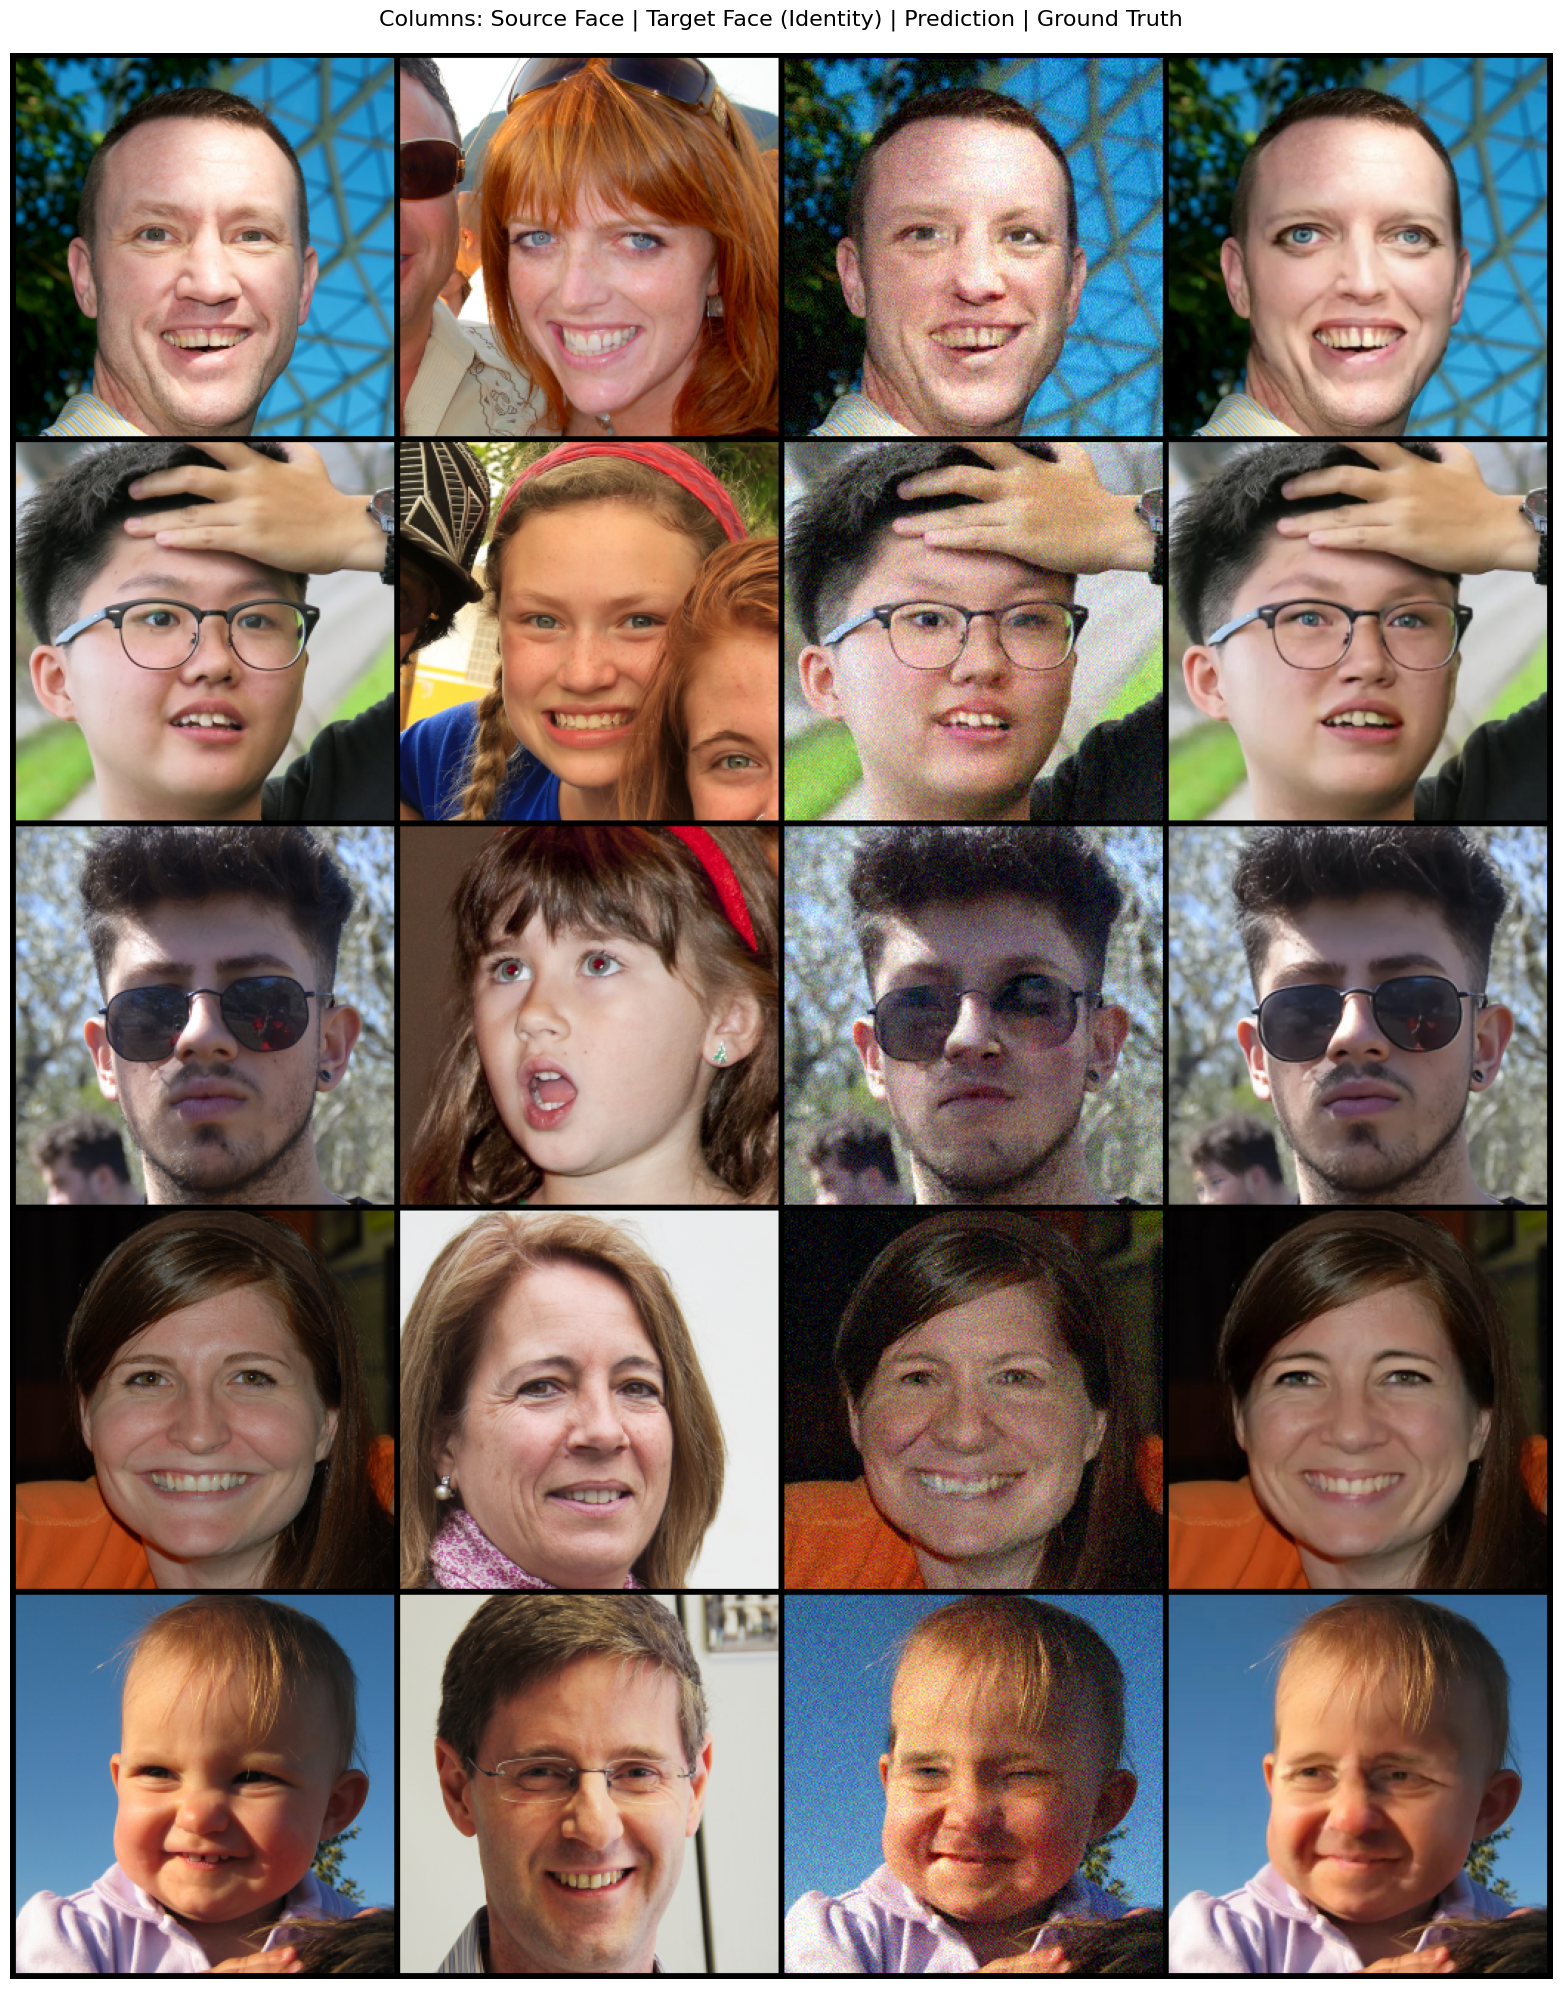

Saved 5 validation samples visualization to: /kaggle/working/rectified_flow_matching/visuals/best_model_5_val_samples.png


In [16]:
# ============================================================
# NEW CELL — 5 Validation Samples using the Best Model
# ============================================================
import matplotlib.pyplot as plt
import torchvision.utils as vutils
import torch

# 1. Load the best checkpoint weights
best_ckpt_path = CKPT_DIR / "best.pt"
if not best_ckpt_path.exists():
    best_ckpt_path = CKPT_DIR / "latest.pt"

print(f"Loading weights from {best_ckpt_path}...")
ckpt = torch.load(best_ckpt_path, map_location=DEVICE,weights_only=False)
flow_model.load_state_dict(ckpt["model"], strict=True)
flow_model.eval()

# 2. Get 5 samples from the validation set
num_vis = 5
val_loader_vis = make_loader(val_ds, batch_size=num_vis, shuffle=True, num_workers=0, drop_last=False)
batch = next(iter(val_loader_vis))

source = batch["source_crop"].to(DEVICE)
gt = batch["ground_truth_crop"].to(DEVICE)
identity = batch["identity"].to(DEVICE)
tgt_indices = batch["tgt_idx"].tolist()

# 3. Generate predictions deterministically
with torch.inference_mode():
    noise = torch.randn_like(source)
    pred = flow_sample(flow_model, source, identity, noise, steps=SAMPLE_STEPS, solver=SAMPLE_SOLVER)

# 4. Denormalize from [-1, 1] noise-space to [0, 1] image-space
def denorm(t):
    return (t.clamp(-1, 1) + 1) / 2.0

source_vis = denorm(source)
pred_vis = denorm(pred)
gt_vis = denorm(gt)

# 5. Fetch target (identity) crops for visualization
# Note: target images are already [0, 1] from load_resized_tensor / crop_from_box
target_crops = []
for t_idx in tgt_indices:
    t_img = load_resized_tensor(ffhq_path(t_idx))
    t_crop = crop_from_box(t_img, face_boxes[t_idx])
    target_crops.append(t_crop)
target_vis = torch.stack(target_crops).to(DEVICE)

# 6. Build a grid (Rows: 5 samples. Cols: Source, Target, Pred, GT)
rows = []
for i in range(num_vis):
    rows.append(torch.stack([source_vis[i], target_vis[i], pred_vis[i], gt_vis[i]]))

grid = vutils.make_grid(torch.cat(rows, dim=0), nrow=4, padding=4, normalize=False)
grid_np = grid.permute(1, 2, 0).cpu().numpy()

# 7. Display and save the plot
plt.figure(figsize=(16, 4 * num_vis))
plt.imshow(grid_np)
plt.axis('off')
plt.title("Columns: Source Face | Target Face (Identity) | Prediction | Ground Truth", fontsize=16, pad=20)
plt.tight_layout()

out_path = VIS_DIR / "best_model_5_val_samples.png"
plt.savefig(out_path, bbox_inches='tight', facecolor='white')
plt.show()

print(f"Saved 5 validation samples visualization to: {out_path}")